## 磁接收机分析

同样的，我们在Maxwell中建模一个磁接收机。我们只使用一个简单的磁芯模型进行理论计算，最终的结果以Maxwell有限元仿真的结果为准。

### 地下雷管磁接收机

地下雷管的磁芯接收机具有如下的参数：

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from magcomm.coil import *
from magcomm.const import Const

ug_coil_default = UGCoil(frequency=4e3)

接下来计算它在磁发射机分析中得到的磁场强度下的开环感应电压：

磁感应强度的结果：

| Position (m)	| B_x (T)	| B_y (T)	| B_z (T) |
| ------------- | ----------- | ----------- | ----------- | 
|[  0 200 -10]	| 0.000000e+00	| 1.194182e-12	| -7.921404e-12 |
|[  0 250 -10]	| 0.000000e+00	| 4.902363e-13	| -4.072230e-12 |
|[  0 300 -10]	| 0.000000e+00	| 2.367067e-13	| -2.361807e-12 |

磁场强度的结果：

| Position (m)	| H_x (A/m)	| H_y (A/m)	| H_z (A/m) |
| ------------- | ----------- | ----------- | ----------- |
| [  0 200 -10]	| 0.000000e+00	| 9.502995e-07	| -6.303653e-06 |
| [  0 250 -10]	| 0.000000e+00	| 3.901177e-07	| -3.240577e-06 |
| [  0 300 -10]	| 0.000000e+00	| 1.883652e-07	| -1.879466e-06 |

最基本的电磁感应公式为：

$ V = -N \frac{d\Phi}{dt} = -N A_{eff} \frac{dB}{dt} $

在正弦激励下，上述式表示为：

$ V = -2\pi f N A_{eff} B_{max} $

In [3]:
distance = [200, 250, 300]
b_z = [7.921404e-12, 4.07223e-12, 2.361807e-12]
h_z = np.array(b_z) / Const.mu0
print(f"|Distance (m)\t| Bz (T)\t| Hz (A/m)\t| Voltage (V)\t|")
print("|------------\t|-------\t|---------\t|------------\t|")
for idx in range(len(distance)):
    v = ug_coil_default.calculate_induced_voltage([b_z[idx]])
    print(f"|{distance[idx]}\t\t| {b_z[idx]:.3e}\t| {h_z[idx]:.3e}\t| {v:.3e}\t|")

|Distance (m)	| Bz (T)	| Hz (A/m)	| Voltage (V)	|
|------------	|-------	|---------	|------------	|
|200		| 7.921e-12	| 6.304e-06	| 8.257e-06	|
|250		| 4.072e-12	| 3.241e-06	| 4.245e-06	|
|300		| 2.362e-12	| 1.879e-06	| 2.462e-06	|


另外还可以计算接收机和发射机之间的互感，用以进行仿真计算：

In [12]:
og_coil_default = OGCoil(frequency=4e3)
ug_coil_tmp = UGCoil(frequency=4e3, center_position=[0, 300, -20])
print(f"互感计算结果：{og_coil_default.calculate_mutual_inductance(ug_coil_tmp)} H")
print(f"地下线圈自身电感计算结果：{ug_coil_tmp.inductance} H")

互感计算结果：9.649054375786855e-12 H
地下线圈自身电感计算结果：0.20846386757333607 H


我们在Maxwell中建模上述的磁接收机，并且在空气盒子的边界上设置指定切向磁场强度的边界条件，来模拟磁发射机的磁场强度。

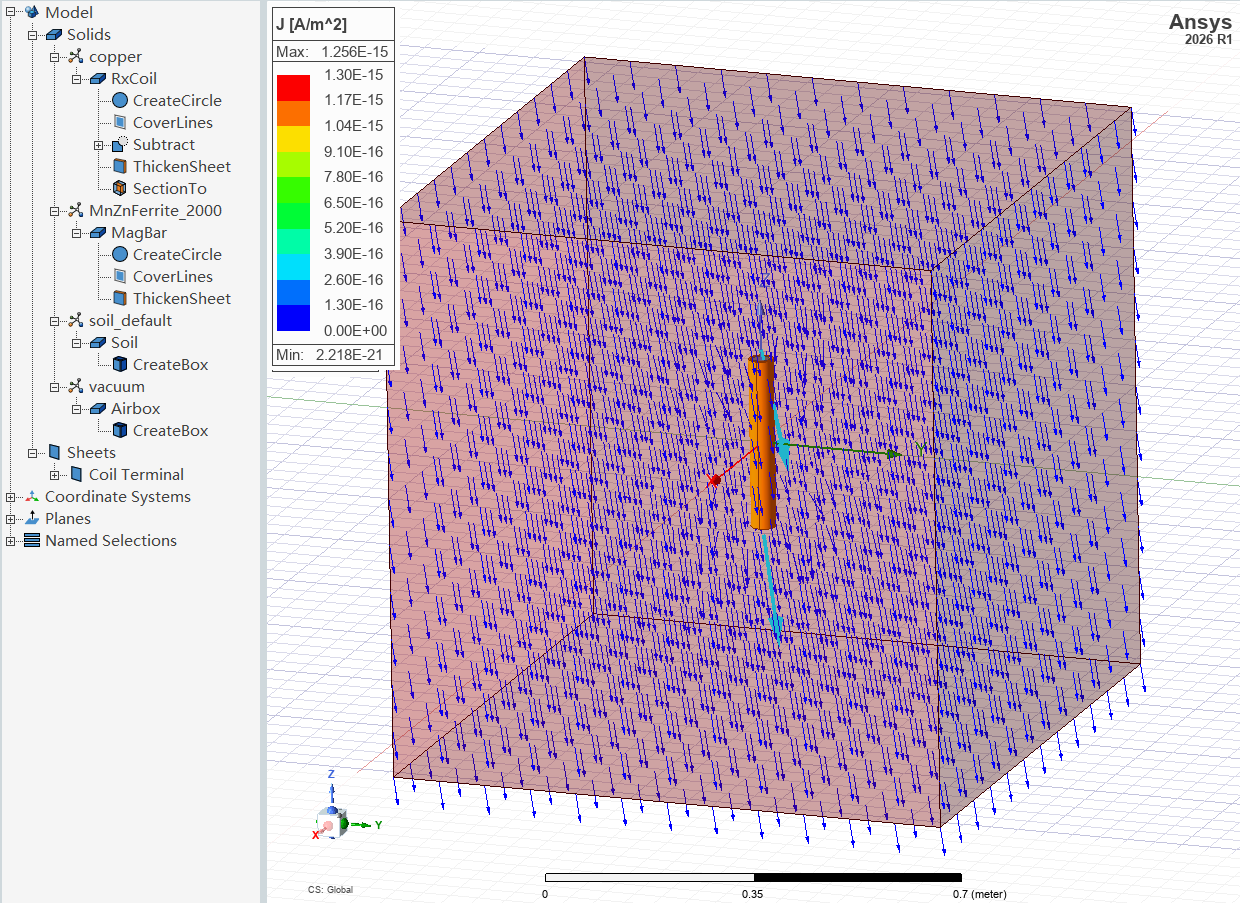

最终得到的开环感应电压结果如下：

| Distance (m)	| Voltage (V) |
| ------------- | ----------- |
| 200 | 9.076e-6 |
| 250 | 4.666e-6 |
| 300 | 2.706e-6 |

计算结果基本上与理论计算结果一致。

再计算一下地面激励线圈和地下线圈的互感（用于后续的ADS仿真）：

In [5]:
og_coil_default = OGCoil(frequency=4e3)

print("|Distance (m)\t| Mutual Inductance (H)\t|")
print("|------------\t|----------------------\t|")
for idx in range(len(distance)):
    ug_coil_temp = UGCoil(frequency=4e3, center_position=(0, distance[idx], -10))
    m = og_coil_default.calculate_mutual_inductance(ug_coil_temp)
    print(f"|{distance[idx]}\t\t| {m:.3e}\t|")

|Distance (m)	| Mutual Inductance (H)	|
|------------	|----------------------	|
|200		| 3.285e-11	|
|250		| 1.689e-11	|
|300		| 9.795e-12	|


接下来计算地面无人车激励下的接收感应电压：

无人车激励的磁感应强度为：

| Position (m) | B_x (T) | B_y (T) | B_z (T) |
| ------------- | ------------- | ------------- | ------------- |
| [0.5 0.  5. ]	| 0.000000e+00	| -1.694494e-09	| 1.124015e-08 |
| [0.5 0.  8. ]	| 0.000000e+00	| -2.625009e-10	| 2.794541e-09 |
| [ 0.5  0.  11. ]	| 0.000000e+00	| -7.377546e-11	| 1.080922e-09 |
| [ 0.5  0.  14. ]	| 0.000000e+00	| -2.817264e-11	| 5.255538e-10 |
| [ 0.5  0.  17. ]	| 0.000000e+00	| -1.297147e-11	| 2.938928e-10 |
| [ 0.5  0.  20. ]	| 0.000000e+00	| -6.775249e-12	| 1.806168e-10 |

磁场强度为：

| Position (m)	| H_x (A/m)	| H_y (A/m)	| H_z (A/m) |
| ------------- | ------------- | ------------- | ------------- |
| [0.5 0.  5. ]	| 0.000000e+00	| -1.348436e-03	| 8.944624e-03 |
| [0.5 0.  8. ]	| 0.000000e+00	| -2.088916e-04	| 2.223825e-03 |
| [ 0.5  0.  11. ]	| 0.000000e+00	| -5.870865e-05	| 8.601706e-04 |
| [ 0.5  0.  14. ]	| 0.000000e+00	| -2.241907e-05	| 4.182224e-04 |
| [ 0.5  0.  17. ]	| 0.000000e+00	| -1.032237e-05	| 2.338724e-04 |
| [ 0.5  0.  20. ]	| 0.000000e+00	| -5.391572e-06	| 1.437303e-04 |

In [6]:
depth = [5, 8, 11, 14, 17, 20]
b_z = [1.124015e-8, 2.794541e-09, 1.080922e-09, 5.255538e-10, 2.938928e-10, 1.806168e-10]
h_z = np.array(b_z) / Const.mu0

print(f"|Distance (m)\t| Bz (T)\t| Hz (A/m)\t| Voltage (V)\t|")
print("|------------\t|-------\t|---------\t|------------\t|")
for idx in range(len(depth)):
    v = ug_coil_default.calculate_induced_voltage([b_z[idx]])
    print(f"|{depth[idx]}\t\t| {b_z[idx]:.3e}\t| {h_z[idx]:.3e}\t| {v:.3e}\t|")

|Distance (m)	| Bz (T)	| Hz (A/m)	| Voltage (V)	|
|------------	|-------	|---------	|------------	|
|5		| 1.124e-08	| 8.945e-03	| 1.172e-02	|
|8		| 2.795e-09	| 2.224e-03	| 2.913e-03	|
|11		| 1.081e-09	| 8.602e-04	| 1.127e-03	|
|14		| 5.256e-10	| 4.182e-04	| 5.478e-04	|
|17		| 2.939e-10	| 2.339e-04	| 3.063e-04	|
|20		| 1.806e-10	| 1.437e-04	| 1.883e-04	|


Maxwell仿真得到的开环感应电压结果如下：

| Depth (m)	| Voltage (V) |
| ------------- | ----------- |
| 5 | 1.288e-2 | 
| 11 | 1.207e-3 |
| 17 | 3.337e-4 |

仿真和理论计算结果基本一致。另外我们可以看到，无人车的磁场可以完全掩盖掉地面基站的磁场强度，这是一个重要的特性！

### 地面中继磁接收机

地面中继磁接收机需要接收雷管发送的上行磁信号，它的线圈参数如下：

In [7]:
uv_coil_default = UVCoil(frequency=3e3)

地面接收机处的磁感应强度为：

| Position (m)	| B_x (T)	| B_y (T)	| B_z (T) |
| ------------- | ------------- | ------------- | ------------- |
| [0.5 0.  5. ]	| 0.000000e+00	| -2.903130e-10	| 1.925743e-09 |
| [0.5 0.  8. ]	| 0.000000e+00	| -4.497354e-11	| 4.787808e-10 |
| [ 0.5  0.  11. ]	| 0.000000e+00	| -1.263974e-11	| 1.851914e-10 |
| [ 0.5  0.  14. ]	| 0.000000e+00	| -4.826739e-12	| 9.004166e-11 |
| [ 0.5  0.  17. ]	| 0.000000e+00	| -2.222365e-12	| 5.035182e-11 |
| [ 0.5  0.  20. ]	| 0.000000e+00	| -1.160784e-12	| 3.094458e-11 |

磁场强度为：

| Position (m)	| H_x (A/m)	| H_y (A/m)	| H_z (A/m) |
| ------------- | ------------- | ------------- | ------------- |
| [0.5 0.  5. ]	| 0.000000e+00	| -2.310237e-04	| 1.532457e-03 |
| [0.5 0.  8. ]	| 0.000000e+00	| -3.578881e-05	| 3.810017e-04 |
| [ 0.5  0.  11. ]	| 0.000000e+00	| -1.005839e-05	| 1.473706e-04 |
| [ 0.5  0.  14. ]	| 0.000000e+00	| -3.840997e-06	| 7.165288e-05 |
| [ 0.5  0.  17. ]	| 0.000000e+00	| -1.768502e-06	| 4.006871e-05 |
| [ 0.5  0.  20. ]	| 0.000000e+00	| -9.237229e-07	| 2.462491e-05 |

仿真计算得到的开环感应电压结果如下：

In [8]:
depth = [5, 8, 11, 14, 17, 20]
b_z = [1.925743e-09, 4.787808e-10, 1.851914e-10, 9.004166e-11, 5.035182e-11, 3.094458e-11]
h_z = np.array(b_z) / Const.mu0

print(f"|Distance (m)\t| Bz (T)\t| Hz (A/m)\t| Voltage (V)\t|")
print("|-------------\t|-------\t|---------\t|------------\t|")
for idx in range(len(depth)):
    v = uv_coil_default.calculate_induced_voltage([b_z[idx]])
    print(f"|{depth[idx]}\t\t| {b_z[idx]:.3e}\t| {h_z[idx]:.3e}\t| {v:.3e}\t|")

|Distance (m)	| Bz (T)	| Hz (A/m)	| Voltage (V)	|
|-------------	|-------	|---------	|------------	|
|5		| 1.926e-09	| 1.532e-03	| 2.627e-04	|
|8		| 4.788e-10	| 3.810e-04	| 6.532e-05	|
|11		| 1.852e-10	| 1.474e-04	| 2.527e-05	|
|14		| 9.004e-11	| 7.165e-05	| 1.229e-05	|
|17		| 5.035e-11	| 4.007e-05	| 6.870e-06	|
|20		| 3.094e-11	| 2.462e-05	| 4.222e-06	|


同样的，使用Maxwell进行仿真，仿真图片如下：

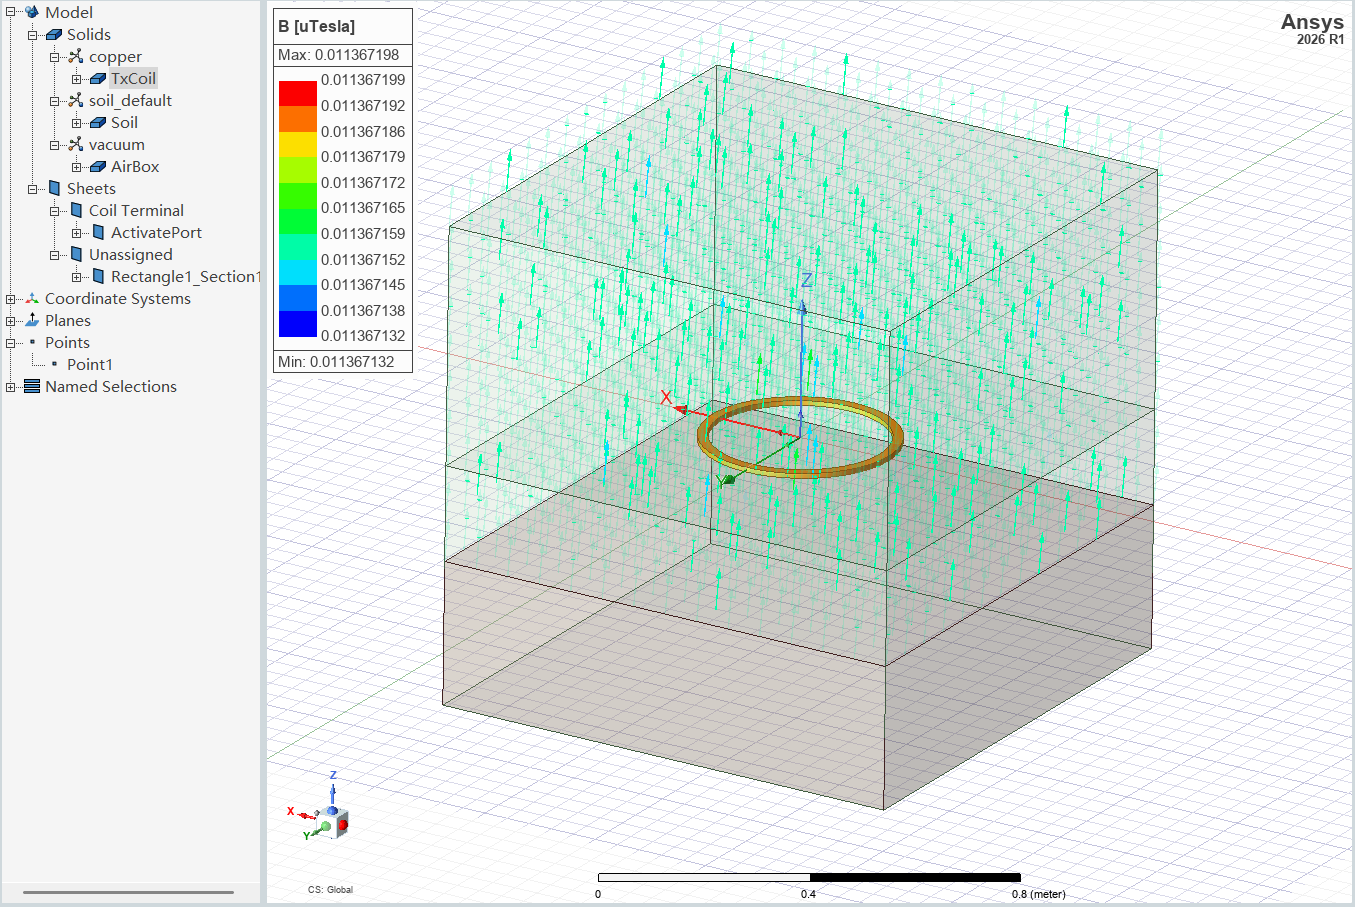

仿真结果为：

| Depth (m)	| Voltage (V) |
| ------------- | ----------- |
| 5 | 2.6064e-4 |
| 11 | 2.5065e-5 |
| 17 | 6.8148e-6 |

仿真结果和理论计算结果基本一致。

### 地面无人车磁接收机的干扰

地面无人车在接收雷管上行信号的同时，也会受到地面基站的下行信号的干扰。考虑到上述已经说明了理论计算的正确性，我们直接使用理论计算的结果来分析干扰的情况。

假定地面无人车相对于单个平躺线圈所在的位置为(0, 200, 0)到(0, 300, 0)，计算地面基站在地面无人车接收机处的磁场强度：

In [9]:
tx_coil_default = OGCoil()
uv_coil_default = UVCoil()

points = np.array([
    [0, 200, 0],
    [0, 250, 0],
    [0, 300, 0],
])
print(f"|Distance (m)\t| Bz (T)\t| Hz (A/m)\t| Voltage (V)\t|")
print("|-------------\t|-------\t|---------\t|------------\t|")
for p in points:
    uv_coil_default.center_position = p
    b_field = tx_coil_default.calculate_magnetic_field(p)
    h_field = b_field / Const.mu0
    b_z = b_field[2]
    h_z = h_field[2]
    v = uv_coil_default.calculate_induced_voltage([b_z])
    print(f"|{p[1]}\t\t| {b_z:.3e}\t| {h_z:.3e}\t| {v:.3e}\t|")
    

|Distance (m)	| Bz (T)	| Hz (A/m)	| Voltage (V)	|
|-------------	|-------	|---------	|------------	|
|200		| -8.011e-12	| -6.375e-06	| 1.457e-06	|
|250		| -4.102e-12	| -3.264e-06	| 7.462e-07	|
|300		| -2.374e-12	| -1.889e-06	| 4.318e-07	|


基站引发的感应电压和雷管引发的感应电压是接近的，因此想要区分二者只能依靠频率的不同。可以用带通滤波、谐振、数字滤波器等方法区分二者的信号。